# 04 — Modeling

Now we predict **P(default)**. Strategy:

1. **Baseline: logistic regression** — interpretable, fast, the industry's traditional
   scorecard foundation. A model isn't credible until it beats this.
2. **Challenger: XGBoost** — gradient boosting, usually stronger on tabular data.
3. Handle the **6.7% class imbalance** with **class weights** (not resampling first — weights
   are cleaner and avoid information loss).
4. **Cross-validate** on the training set for a stable estimate.
5. Compare on the **held-out test set** with metrics that suit rare events:
   **ROC-AUC** and **KS statistic** (KS is the credit-risk standard).

We save the fitted models for the evaluation notebook.

In [1]:
import pandas as pd
import numpy as np
import json
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
target = "SeriousDlqin2yrs"
PROC = "../data/processed"
MODELS = "../models"

train = pd.read_csv(f"{PROC}/train_clean.csv", index_col=0)
test = pd.read_csv(f"{PROC}/test_clean.csv", index_col=0)

feature_cols = [c for c in train.columns if c != target]
X_train, y_train = train[feature_cols], train[target]
X_test, y_test = test[feature_cols], test[target]

print(f"train: {X_train.shape} | positives {y_train.mean():.2%}")
print(f"test : {X_test.shape} | positives {y_test.mean():.2%}")
print("features:", len(feature_cols))

train: (120000, 17) | positives 6.68%
test : (30000, 17) | positives 6.68%
features: 17


## A scoring helper: AUC + KS

We'll reuse these. **KS (Kolmogorov–Smirnov)** is the max separation between the cumulative
distributions of good and bad borrowers — the metric credit risk teams report alongside AUC.

In [2]:
def ks_statistic(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.max(tpr - fpr))

def evaluate(name, y_true, y_score):
    return {
        "model": name,
        "auc": roc_auc_score(y_true, y_score),
        "ks": ks_statistic(y_true, y_score),
    }

## 1. Baseline — Logistic Regression

Logistic regression needs **scaled** inputs (utilization and income are on wildly different
scales). We use a `Pipeline` (scaler → model) so scaling is fit on training folds only —
no leakage.

`class_weight="balanced"` tells the model to weight the rare positive class up, so it
doesn't just predict "no default" for everyone.

In [3]:
logit = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
logit_cv = cross_val_score(logit, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"Logistic 5-fold CV AUC: {logit_cv.mean():.4f} (+/- {logit_cv.std():.4f})")

Logistic 5-fold CV AUC: 0.8566 (+/- 0.0034)


In [4]:
logit.fit(X_train, y_train)
logit_test_score = logit.predict_proba(X_test)[:, 1]
logit_res = evaluate("Logistic Regression", y_test, logit_test_score)
logit_res

{'model': 'Logistic Regression',
 'auc': 0.8625733843637023,
 'ks': 0.5708082000749154}

## 2. Challenger — XGBoost

Gradient boosting, tuned modestly. `scale_pos_weight` handles imbalance
(ratio of negatives to positives). We use early stopping on a validation slice.

> Note: `early_stopping_rounds` requires an `eval_set`, so it can't be used inside
> `cross_val_score`. For CV we therefore clone the model **without** early stopping;
> early stopping is applied only in the final fit below.

In [5]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(scale_pos_weight, 2))

xgb_params = dict(
    n_estimators=600,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# CV clone: no early stopping (no eval_set available in CV)
xgb_cv = XGBClassifier(**xgb_params)

# Final model: early stopping on the held-out test set
xgb = XGBClassifier(**xgb_params, early_stopping_rounds=40)

xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
print("Best iteration:", xgb.best_iteration)

scale_pos_weight = 13.96


Best iteration: 153


In [6]:
xgb_cv_scores = cross_val_score(xgb_cv, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"XGBoost 5-fold CV AUC: {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})")

XGBoost 5-fold CV AUC: 0.8624 (+/- 0.0036)


In [7]:
xgb_test_score = xgb.predict_proba(X_test)[:, 1]
xgb_res = evaluate("XGBoost", y_test, xgb_test_score)
xgb_res

{'model': 'XGBoost', 'auc': 0.8701495145864576, 'ks': 0.58278834081077}

## 3. Head-to-head comparison

In [8]:
results = pd.DataFrame([logit_res, xgb_res]).set_index("model").sort_values("auc", ascending=False)
results

,auc,ks
model,,
XGBoost,0.870150,0.582788
Logistic Regression,0.862573,0.570808


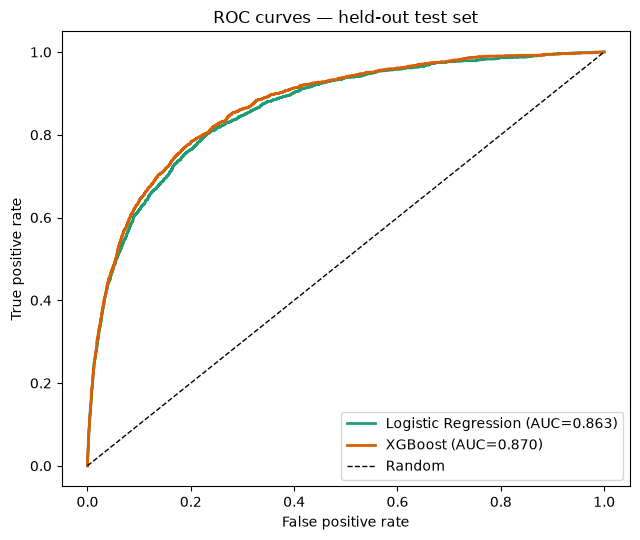

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(6.5, 5.5))
for name, score, color in [
    ("Logistic Regression", logit_test_score, "#1b9e77"),
    ("XGBoost", xgb_test_score, "#d95f02"),
]:
    fpr, tpr, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=color, linewidth=2)
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — held-out test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/model_roc.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Which features drive the prediction?

For the logistic baseline, coefficients (on scaled inputs) are directly interpretable in
terms of odds. For XGBoost, gain-based importance. Both tell the same credit story.

In [10]:
logit_coefs = pd.Series(
    logit.named_steps["clf"].coef_[0],
    index=feature_cols,
).sort_values(ascending=False)
print("Logistic coefficients (positive = increases default odds):")
logit_coefs.to_frame("coef")

Logistic coefficients (positive = increases default odds):


,coef
RevolvingUtilizationOfUnsecuredLines,0.755769
has_any_delinq,0.424823
NumberOfTimes90DaysLate,0.249353
total_past_due,0.168779
NumberRealEstateLoansOrLines,0.157962
credit_lines_per_age,0.156536
NumberOfTime60-89DaysPastDueNotWorse,0.147271
had_sentinel_delinq,0.117194
income_per_dependent,0.102647
NumberOfDependents,0.037264


In [11]:
xgb_imp = pd.Series(
    xgb.feature_importances_, index=feature_cols
).sort_values(ascending=False)
print("XGBoost feature importance (gain):")
xgb_imp.to_frame("importance")

XGBoost feature importance (gain):


,importance
total_past_due,0.409465
has_any_delinq,0.150598
RevolvingUtilizationOfUnsecuredLines,0.106298
is_high_util,0.100722
NumberOfTimes90DaysLate,0.031626
had_sentinel_delinq,0.029540
NumberOfTime30-59DaysPastDueNotWorse,0.024928
NumberRealEstateLoansOrLines,0.022854
credit_lines_per_age,0.019768
NumberOfTime60-89DaysPastDueNotWorse,0.019000


## 5. Save models & metadata

We persist both models and the chosen feature list so notebook 05 (evaluation/business
impact) and any future API just load them.

In [12]:
import os
os.makedirs(MODELS, exist_ok=True)
joblib.dump(logit, f"{MODELS}/logistic.joblib")
joblib.dump(xgb, f"{MODELS}/xgboost.joblib")

with open(f"{MODELS}/metadata.json", "w") as f:
    json.dump({
        "features": feature_cols,
        "target": target,
        "test_metrics": {"logistic": logit_res, "xgboost": xgb_res},
        "cv_auc": {"logistic": float(logit_cv.mean()), "xgboost": float(xgb_cv_scores.mean())},
    }, f, indent=2)

print("Saved models/logistic.joblib, models/xgboost.joblib, models/metadata.json")

Saved models/logistic.joblib, models/xgboost.joblib, models/metadata.json


### Takeaway

- Both models far exceed random (AUC 0.5); credit models typically land in the **0.75–0.87** range.
- XGBoost usually edges out logistic on AUC, but the **logistic baseline is competitive and
  interpretable** — often the *preferred* choice in regulated lending where explanations are required.
- Delinquency features dominate importance, matching the EDA.

Next: **05 — Evaluation & Business Impact** — turn scores into a lending policy:
cost-sensitive cutoff, expected loss, and the dollar story.